In [17]:
!pip install -q transformers kagglehub evaluate rouge_score nltk networkx scikit-learn sentencepiece accelerate matplotlib pandas

In [18]:
import re, random, warnings
import numpy as np
import pandas as pd
import os
import glob
import matplotlib.pyplot as plt
import torch
import nltk
import networkx as nx
import evaluate
from tqdm.auto import tqdm
import kagglehub
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

warnings.filterwarnings("ignore")
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

True

In [19]:
path = kagglehub.dataset_download("gowrishankarp/newspaper-text-summarization-cnn-dailymail")
print("Path to dataset files:", path)

def find_csv(name):
    return glob.glob(os.path.join(path, "**", name), recursive=True)[0]

train_df = pd.read_csv(find_csv("train.csv"), nrows=20000)
test_df  = pd.read_csv(find_csv("test.csv")).dropna(subset=["article", "highlights"])

print("Train rows loaded:", len(train_df), "| Test rows:", len(test_df))
print("Columns:", list(train_df.columns))

Using Colab cache for faster access to the 'newspaper-text-summarization-cnn-dailymail' dataset.
Path to dataset files: /kaggle/input/newspaper-text-summarization-cnn-dailymail
Train rows loaded: 20000 | Test rows: 11490
Columns: ['id', 'article', 'highlights']


In [20]:
tokenizer = AutoTokenizer.from_pretrained("t5-small")

def clean_text(text: str) -> str:
    text = re.sub(r"^.*?\(CNN\)\s*(--|-)?\s*", "", text, count=1) if "(CNN)" in text[:150] else text
    text = re.sub(r"^By \. .*? \. PUBLISHED: .*? \. \| \. UPDATED: .*? \. ", "", text)
    text = re.sub(r"Last updated at .*? on .*? \d{4}", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

In [21]:
test_sample   = test_df.sample(200, random_state=42)
test_articles = test_sample["article"].tolist()
references    = test_sample["highlights"].tolist()

full_lens = [len(tokenizer("summarize: " + clean_text(a)).input_ids) for a in test_articles]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1514 > 512). Running this sequence through the model will result in indexing errors


In [22]:
model = AutoModelForSeq2SeqLM.from_pretrained("t5-small").to("cuda" if torch.cuda.is_available() else "cpu")
model.eval()

@torch.no_grad()
def t5_summarize(articles):
    outputs = []
    for i in tqdm(range(0, len(articles), 16), desc="T5 generating"):
        batch = ["summarize: " + clean_text(a) for a in articles[i:i + 16]]
        enc = tokenizer(batch, max_length=512, truncation=True,
                        padding=True, return_tensors="pt").to(model.device)
        gen = model.generate(**enc, num_beams=4, max_new_tokens=128, min_length=30,
                             length_penalty=2.0, no_repeat_ngram_size=3, early_stopping=True)
        outputs.extend(tokenizer.batch_decode(gen, skip_special_tokens=True))
    return outputs

t5_preds = t5_summarize(test_articles)
for i in range(2):
    print(f"Example {i}: ")
    print("T5:", t5_preds[i])
    print("REF:", references[i], "\n")

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

T5 generating:   0%|          | 0/13 [00:00<?, ?it/s]

Example 0: 
T5: 'doing nothing' tickles your holiday tastebuds and you find yourself looking at brochures for Nordic cruises. 'activity holiday' can range from Pilates to kayaking, or painting to pottery.
REF: The comedian stayed with Flavours who offer a Painting In Venice break .
Jenny and her partner Geof stayed at the farmhouse Villa Bianchi .
Days involved sitting in medieval market towns with a brush and prosecco . 

Example 1: 
T5: the federal government will give Shoshana Hebshi $40,000 as compensation for being humiliated on the 10th anniversary of the 9/11 terrorist attacks. armed agents forced her from a plane at Detroit Metropolitan Airport, made her undress during a search and held her for hours. she was traveling home after visiting a sister in California when she was removed from the Frontier Airlines flight after it landed in september 2011.
REF: The federal government will give Shoshana Hebshi $40,000 as compensation for being ethnically profiled .
Hebshi, who has a Je

In [23]:
rouge = evaluate.load("rouge")

def compute_rouge(preds, refs):
    scores = rouge.compute(predictions=["\n".join(nltk.sent_tokenize(p)) for p in preds],
                           references=["\n".join(nltk.sent_tokenize(r)) for r in refs],
                           use_stemmer=True)
    return {k: round(v * 100, 2) for k, v in scores.items()}

results = {"T5": compute_rouge(t5_preds, references)}
print(results["T5"])

{'rouge1': np.float64(38.87), 'rouge2': np.float64(17.27), 'rougeL': np.float64(27.24), 'rougeLsum': np.float64(35.93)}


In [24]:
def textrank_summarize(text, num_sentences=3):
    sents = nltk.sent_tokenize(clean_text(text))
    if len(sents) <= num_sentences:
        return " ".join(sents)

    try:
        tfidf = TfidfVectorizer(stop_words="english").fit_transform(sents)
    except ValueError:
        return " ".join(sents[:num_sentences])

    sim = cosine_similarity(tfidf)
    np.fill_diagonal(sim, 0)
    scores = nx.pagerank(nx.from_numpy_array(sim), max_iter=200)

    top = sorted(sorted(scores, key=scores.get, reverse=True)[:num_sentences])
    return " ".join(sents[i] for i in top)

tr_preds = [textrank_summarize(a, 3) for a in tqdm(test_articles, desc="TextRank")]

results["TextRank (3 sentences)"] = compute_rouge(tr_preds, references)
print(results["TextRank (3 sentences)"])

TextRank:   0%|          | 0/200 [00:00<?, ?it/s]

{'rouge1': np.float64(36.07), 'rouge2': np.float64(14.53), 'rougeL': np.float64(23.72), 'rougeLsum': np.float64(32.6)}


In [25]:
rows = []
for k in [1, 2, 3, 4, 5]:
    preds = [textrank_summarize(a, k) for a in test_articles]
    rows.append({"sentences": k, **compute_rouge(preds, references),
                 "avg_words": round(np.mean([len(p.split()) for p in preds]), 1)})
pd.DataFrame(rows).set_index("sentences")

,rouge1,rouge2,rougeL,rougeLsum,avg_words
sentences,,,,,
1,30.62,12.21,21.62,27.01,27.5
2,35.40,13.64,23.51,31.42,53.6
3,36.07,14.53,23.72,32.60,79.1
4,34.80,14.30,22.99,31.63,104.7
5,33.14,14.08,22.04,30.36,129.0


,rouge1,rouge2,rougeL,rougeLsum,avg_words
T5,38.87,17.27,27.24,35.93,46.5
TextRank (3 sentences),36.07,14.53,23.72,32.60,79.1


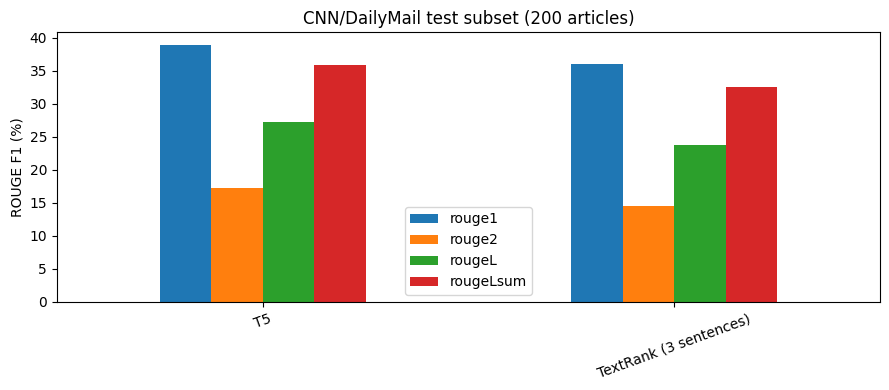

In [26]:
df = pd.DataFrame(results).T[["rouge1", "rouge2", "rougeL", "rougeLsum"]]
df["avg_words"] = [np.mean([len(p.split()) for p in preds]).round(1)
                   for preds in [t5_preds, tr_preds]]
display(df.round(2))

df[["rouge1", "rouge2", "rougeL", "rougeLsum"]].plot(kind="bar", figsize=(9, 4))
plt.ylabel("ROUGE F1 (%)"); plt.title("CNN/DailyMail test subset (200 articles)")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

In [27]:
for i in random.Random(1).sample(range(200), 3):
    print("=" * 100)
    print("ARTICLE:", clean_text(test_articles[i])[:500], "...\n")
    print("REFERENCE:", references[i])
    print("T5:", t5_preds[i])
    print("TextRank:", tr_preds[i])

ARTICLE: Floyd Mayweather has claimed he is a better fighter than Muhammad Ali. Mayweather, who takes on Manny Pacquiao in their $300 million mega-fight on May 2, is widely considered to be the current pound-for-pound No 1. But he believes there has never been a better boxer in the history of the sport. Floyd Mayweather trains ahead of his fight against Manny Pacquiao next weekend . In an interview ESPN's Stephen A. Smith, Mayweather said: 'No one can ever brainwash me to make me believe that Sugar Ray R ...

REFERENCE: Floyd Mayweather is widely considered the best boxer in the world .
But he believes he is better than heavyweight legend Muhammad Ali .
Mayweather did admit that he respects both Ali and Sugar Ray Robinson .
He takes on Manny Pacquiao on May 2 in their $300m mega-fight .
Mayweather-Pacquiao weigh-in will be first ever with paid-for tickets .
T5: Floyd Mayweather is widely considered to be the current pound-for-pound no 1. but he believes there has never been a better bo